# Mini Project 1: Predicting News Article Shares

**Goal:** predict `shares` (how many times an article was shared) from the article's statistics.

This notebook is the exploratory data analysis (EDA). It answers three questions before any modelling:
1. Is the data clean enough to trust?
2. What does the target look like?
3. Which features look useful, and which could mislead the model?

## 1. Setup

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)  # show every column, not just the first and last few

df = pd.read_csv("./data/data.csv")

## 2. First look

In [ ]:
print("Rows, columns:", df.shape)
df.head()

Rows, columns: (35680, 30)


,ID,URL,timedelta,weekday,shares,n_tokens_title,n_tokens_content,n_unique_tokens,n_non_stop_words,n_non_stop_unique_tokens,num_hrefs,num_self_hrefs,num_imgs,num_videos,n_comments,average_token_length,data_channel,self_reference_min_shares,self_reference_max_shares,self_reference_avg_shares,num_keywords,kw_min_min,kw_max_min,kw_avg_min,kw_min_max,kw_max_max,kw_avg_max,kw_min_avg,kw_max_avg,kw_avg_avg
0,0,http://mashable.com/2013/01/07/amazon-instant-...,731.0,monday,593,12.0,219.0,0.663594,1.0,0.815385,4.0,2.0,1.0,0.0,0.0,4.680365,entertainment,496.0,496.0,496.000000,5.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,1,http://mashable.com/2013/01/07/ap-samsung-spon...,731.0,monday,711,9.0,255.0,0.604743,1.0,0.791946,3.0,1.0,1.0,NaN,28.0,4.913725,business,0.0,0.0,0.000000,4.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,2,http://mashable.com/2013/01/07/apple-40-billio...,731.0,monday,1500,9.0,211.0,0.575130,1.0,0.663866,3.0,1.0,1.0,0.0,15.0,4.393365,business,918.0,918.0,918.000000,6.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,3,http://mashable.com/2013/01/07/astronaut-notre...,731.0,monday,1200,9.0,531.0,0.503788,1.0,0.665635,9.0,0.0,1.0,0.0,72.0,4.404896,entertainment,0.0,0.0,0.000000,7.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,4,http://mashable.com/2013/01/07/att-u-verse-apps/,731.0,monday,505,13.0,1072.0,0.415646,1.0,0.540890,19.0,19.0,20.0,NaN,20.0,4.682836,technology,545.0,16000.0,3151.157895,7.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [ ]:
# Column names, how many non-empty values each has, and the data type
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 35680 entries, 0 to 35679
Data columns (total 30 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   ID                         35680 non-null  int64  
 1   URL                        35680 non-null  object 
 2   timedelta                  35680 non-null  float64
 3   weekday                    35680 non-null  object 
 4   shares                     35680 non-null  int64  
 5   n_tokens_title             35680 non-null  float64
 6   n_tokens_content           35680 non-null  float64
 7   n_unique_tokens            35680 non-null  float64
 8   n_non_stop_words           35680 non-null  float64
 9   n_non_stop_unique_tokens   35680 non-null  float64
 10  num_hrefs                  34959 non-null  float64
 11  num_self_hrefs             34959 non-null  float64
 12  num_imgs                   34261 non-null  float64
 13  num_videos                 18925 non-null  flo

## 3. Data quality

### 3.1 Missing values

In [ ]:
missing = df.isna().sum()                      # count of empty cells per column
missing_pct = (missing / len(df) * 100).round(1)  # same, as a percentage of all rows

missing_table = pd.DataFrame({"missing": missing, "pct": missing_pct})
missing_table[missing_table["missing"] > 0].sort_values("missing", ascending=False)

,missing,pct
num_videos,16755,47.0
data_channel,5462,15.3
num_imgs,1419,4.0
num_hrefs,721,2.0
num_self_hrefs,721,2.0
self_reference_min_shares,721,2.0
self_reference_max_shares,721,2.0
self_reference_avg_shares,721,2.0


### 3.2 Do some columns go missing together?

In [ ]:
link_cols = ["num_hrefs", "num_self_hrefs",
             "self_reference_min_shares", "self_reference_max_shares", "self_reference_avg_shares"]

# For each row, count how many of these 5 columns are empty
df[link_cols].isna().sum(axis=1).value_counts()

0    34959
5      721
Name: count, dtype: int64

### 3.3 Duplicates

In [ ]:
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate IDs: ", df["ID"].duplicated().sum())
print("Duplicate URLs:", df["URL"].duplicated().sum())

Duplicate rows: 0
Duplicate IDs:  0
Duplicate URLs: 0


### 3.4 Impossible or suspicious values

In [ ]:
# min, quartiles and max for every numeric column
df.describe().T

,count,mean,std,min,25%,50%,75%,max
ID,35680.0,19823.468918,11452.292291,0.0,9890.750000,19801.500000,29788.250000,39643.000000
timedelta,35680.0,354.523234,214.301086,8.0,163.000000,339.000000,543.000000,731.000000
shares,35680.0,3402.054961,11934.878541,4.0,946.000000,1400.000000,2800.000000,843300.000000
n_tokens_title,35680.0,10.395432,2.114600,2.0,9.000000,10.000000,12.000000,23.000000
n_tokens_content,35680.0,545.995123,469.550052,0.0,247.000000,410.000000,716.000000,8474.000000
n_unique_tokens,35680.0,0.530461,0.136935,0.0,0.471030,0.539011,0.608203,1.000000
n_non_stop_words,35680.0,0.970263,0.169862,0.0,1.000000,1.000000,1.000000,1.000000
n_non_stop_unique_tokens,35680.0,0.672738,0.153881,0.0,0.625912,0.690323,0.754036,1.000000
num_hrefs,34959.0,10.866358,11.260971,0.0,4.000000,8.000000,14.000000,304.000000
num_self_hrefs,34959.0,3.282531,3.834065,0.0,1.000000,3.000000,4.000000,116.000000


In [ ]:
numeric = df.select_dtypes("number")

# Counts and shares can never be negative. Which columns have negative values?
negatives = (numeric < 0).sum()
negatives[negatives > 0]

kw_min_min    20660
kw_avg_min      767
kw_min_avg        6
dtype: int64

In [ ]:
print("Articles with 0 words of content:", (df["n_tokens_content"] == 0).sum())

Articles with 0 words of content: 1061


**Findings**
- `num_videos` is blank in 47% of rows and `data_channel` in 15%. `num_imgs` is blank in 4%.
- Five link columns are blank on the same 721 rows (2%). That is one gap, not five.
- `kw_min_min` is -1 in 58% of rows. Shares cannot be negative, so -1 is a no-data marker. `kw_avg_min` and `kw_min_avg` carry a few negatives from the same marker.
- 1,061 articles have 0 words. They look like photo or video posts, so I keep them.
- No duplicates. `ID` and `URL` are labels, not clues.

## 4. The target: `shares`

In [ ]:
df["shares"].describe()

count     35680.000000
mean       3402.054961
std       11934.878541
min           4.000000
25%         946.000000
50%        1400.000000
75%        2800.000000
max      843300.000000
Name: shares, dtype: float64

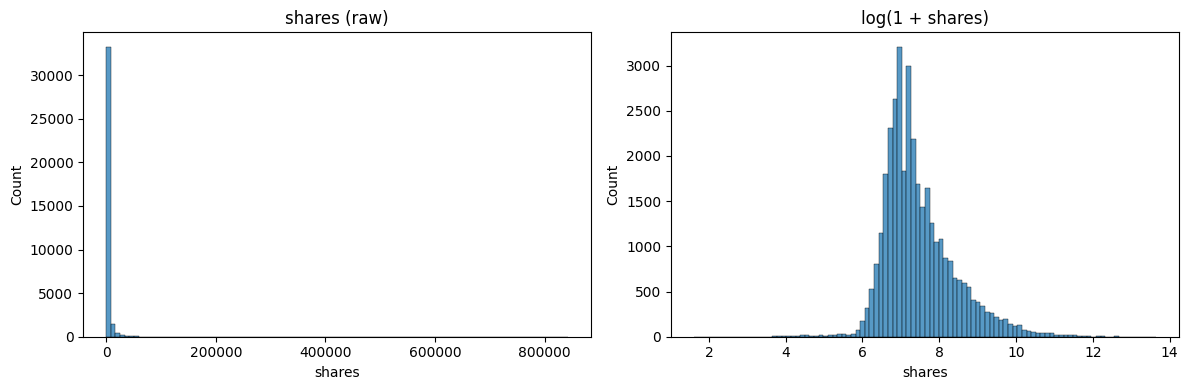

Skew, raw: 34.41
Skew, log: 1.04


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(df["shares"], bins=100, ax=axes[0])
axes[0].set_title("shares (raw)")

sns.histplot(np.log1p(df["shares"]), bins=100, ax=axes[1])  # log1p(x) = log(1 + x)
axes[1].set_title("log(1 + shares)")

plt.tight_layout()
plt.show()

print("Skew, raw:", round(df["shares"].skew(), 2))
print("Skew, log:", round(np.log1p(df["shares"]).skew(), 2))

In [ ]:
# The 10 most-shared articles
df.nlargest(10, "shares")[["URL", "shares", "data_channel", "weekday"]]

,URL,shares,data_channel,weekday
8438,http://mashable.com/2013/07/03/low-cost-iphone/,843300,NaN,wednesday
4848,http://mashable.com/2013/04/15/dove-ad-beauty-...,690400,business,monday
20927,http://mashable.com/2014/04/09/first-100-gilt-...,663600,technology,wednesday
14666,http://mashable.com/2013/11/18/kanye-west-harv...,652900,business,monday
2828,http://mashable.com/2013/03/02/wealth-inequality/,617900,NaN,saturday
14433,http://mashable.com/2013/11/12/roomba-880-review/,441000,NaN,tuesday
16932,http://mashable.com/2014/01/14/australia-heatw...,310800,business,tuesday
4065,http://mashable.com/2013/03/28/blackberry-1-mi...,306100,business,thursday
14524,http://mashable.com/2013/11/14/ibm-watson-brief/,298400,business,thursday
31724,http://mashable.com/2014/10/22/ebola-cdc-activ...,284700,world,thursday


**Findings**
- `shares` is heavily right-skewed. Half the articles get 1,400 shares or fewer, but a few went viral, up to 843,300.
- A model trained on raw shares would chase those few viral articles and get worse on normal ones.
- On the log scale the shape is close to a bell curve (skew drops from 34 to 1). **Decision: train on log(1 + shares)**, then convert predictions back to shares.

## 5. Categories: `weekday` and `data_channel`

In [ ]:
df["weekday"].value_counts(dropna=False)

weekday
wednesday    6663
tuesday      6646
thursday     6563
monday       5977
friday       5147
sunday       2472
saturday     2212
Name: count, dtype: int64

In [ ]:
df["data_channel"].value_counts(dropna=False)

data_channel
world            7573
technology       6642
entertainment    6407
business         5623
NaN              5462
social_media     2089
lifestyle        1884
Name: count, dtype: int64

In [ ]:
# Do articles with no channel behave like random gaps, or like a group of their own?
df.groupby(df["data_channel"].fillna("MISSING"))["shares"].median().sort_values()

data_channel
world            1100.0
entertainment    1200.0
business         1400.0
lifestyle        1700.0
technology       1700.0
MISSING          1900.0
social_media     2100.0
Name: shares, dtype: float64

**Findings**
- Articles with no topic have a median of 1,900 shares, higher than most labelled topics. They behave like a group of their own.
- **Decision: keep them as their own `no_topic` category.** Deleting them loses 15% of the data. Labelling them "world" would be wrong, because world has the lowest median (1,100).

## 6. When is each column known?

A predictor is most useful **before** an article is published. Every column describes the article itself, except one: `n_comments`. Reader comments only arrive after publishing, at the same time as shares.

Section 9 measures how much this one column changes the result.

## 7. Testing what the blanks mean

In [ ]:
# Is a blank video count the same as 0 videos? Compare average shares for the three groups.
video_group = np.where(df["num_videos"].isna(), "blank",
              np.where(df["num_videos"] == 0, "0 videos", "1+ videos"))
df.groupby(video_group)["shares"].agg(["count", "mean", "median"]).round(0)

,count,mean,median
0 videos,11894,2822.0,1400.0
1+ videos,7031,4282.0,1500.0
blank,16755,3445.0,1400.0


In [ ]:
# Does the -1 marker in kw_min_min tell us anything about shares?
has_marker = df["kw_min_min"] == -1
print(df.groupby(has_marker)["shares"].mean().round(0))

# Where do the -1 rows sit in time? (timedelta = days between publishing and data collection)
df.groupby(has_marker)["timedelta"].agg(["min", "max"])

kw_min_min
False    3433.0
True     3379.0
Name: shares, dtype: float64


,min,max
kw_min_min,,
False,255.0,731.0
True,8.0,408.0


**Findings**
- Blank video counts: the blank group's average shares (3,445) sits between 0 videos (2,822) and 1+ videos (4,282). So blank means "not recorded", a mix of both. **Decision: fill with 0 and add a `num_videos_missing` flag**, because articles with videos get about 50% more shares and I want to keep that signal.
- `kw_min_min`: average shares are about the same with the marker (3,379) and without (3,433). Every -1 is on a newer article, so it reflects how the site recorded data, not the article. **Decision: drop the column.**

## 8. Which clues relate to shares?

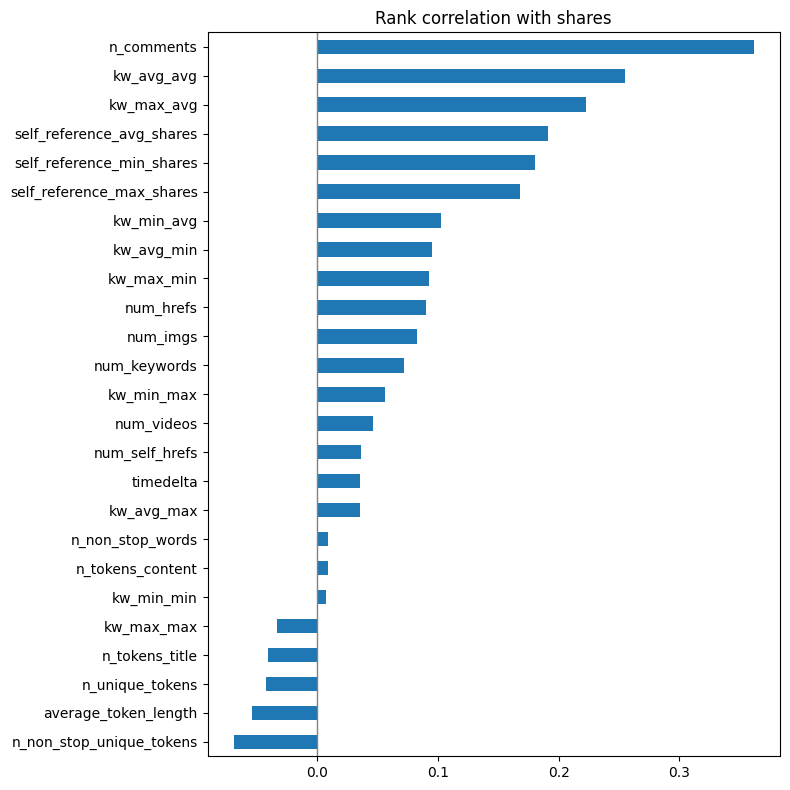

In [ ]:
# Rank correlation of each numeric column with shares.
# Spearman is used because it is not thrown off by the viral outliers.
correlations = (df.select_dtypes("number")
                  .drop(columns=["ID"])
                  .corr(method="spearman")["shares"]
                  .drop("shares")
                  .sort_values())

correlations.plot(kind="barh", figsize=(8, 8))
plt.title("Rank correlation with shares")
plt.axvline(0, color="grey", linewidth=1)
plt.tight_layout()
plt.show()

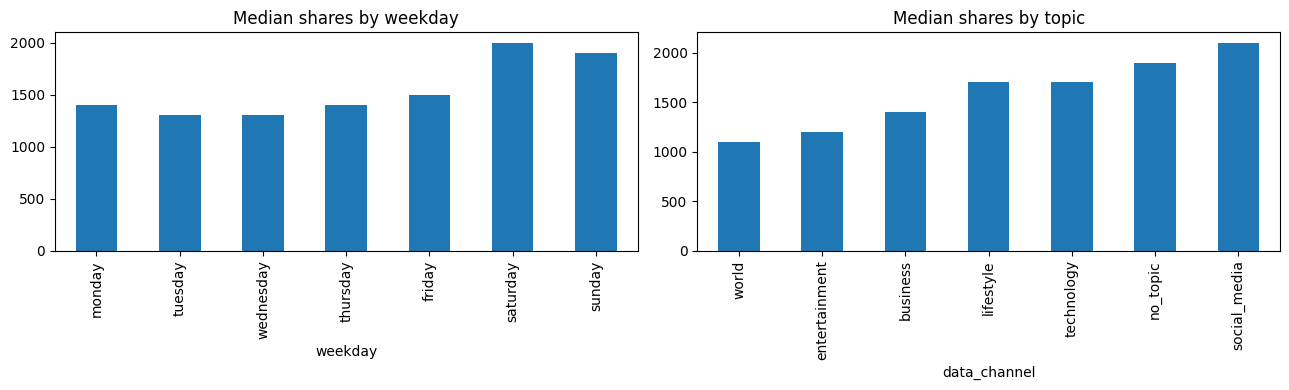

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

day_order = ["monday", "tuesday", "wednesday", "thursday", "friday", "saturday", "sunday"]
df.groupby("weekday")["shares"].median().reindex(day_order).plot(kind="bar", ax=axes[0])
axes[0].set_title("Median shares by weekday")

(df.groupby(df["data_channel"].fillna("no_topic"))["shares"]
   .median().sort_values().plot(kind="bar", ax=axes[1]))
axes[1].set_title("Median shares by topic")

plt.tight_layout()
plt.show()

**Findings**
- No single clue is strong. The best pre-publication clues are the keyword averages (`kw_avg_avg`, `kw_max_avg`) and the shares of articles this one links to (`self_reference_*`), with rank correlations between 0.17 and 0.25.
- Weekend articles get more shares (median about 2,000 on Saturday against 1,300 to 1,400 midweek), although fewer are published.
- Topic matters: social media and lifestyle sit near the top, world and entertainment at the bottom.
- `n_comments` is the strongest of all (0.36), which is expected because comments and shares happen together.

**What this means for modelling:** shares are hard to predict from the article alone, so I expect modest scores. I should compare every model against a simple baseline to see if it has learned anything.

## 9. How much do reader comments matter?

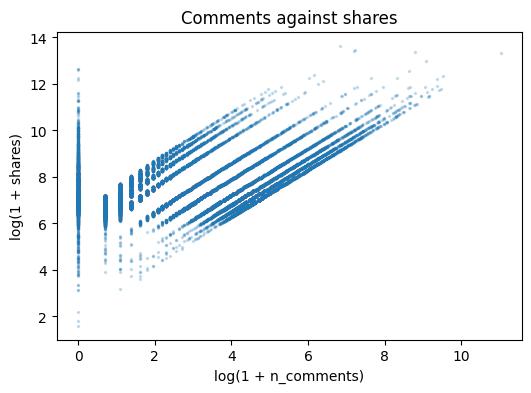

In [ ]:
plt.figure(figsize=(6, 4))
plt.scatter(np.log1p(df["n_comments"]), np.log1p(df["shares"]), s=2, alpha=0.2)
plt.xlabel("log(1 + n_comments)")
plt.ylabel("log(1 + shares)")
plt.title("Comments against shares")
plt.show()

**Findings**
- More comments go with more shares. But comments are only known after publishing.
- **Decision: run the pipeline for two scenarios** and report both honestly.
  - **A. Before publishing:** no `n_comments`. This is the model an editor can use on a draft.
  - **B. After publishing:** `n_comments` included. Useful only once an article is live, for example to spot early which ones to promote.

## 10. Summary of decisions carried into the pipeline

| Issue | Decision | Reason |
| --- | --- | --- |
| `ID`, `URL` | Drop | Labels, not clues |
| `kw_min_min` (58% are -1) | Drop | Placeholder values, no link to shares |
| `num_videos` (47% blank) | Fill with 0, add a missing flag | Blank means not recorded. Videos relate to shares |
| `data_channel` (15% blank) | Own category `no_topic` | Behaves like its own group |
| `num_imgs` and 5 link columns (blank in 2 to 4%) | Fill with the training median | Small gaps, not worth losing rows |
| Negatives in `kw_avg_min`, `kw_min_avg` | Set to 0 | Share counts cannot be negative |
| 0-word articles | Keep | Likely photo or video posts |
| `shares` skew | Train on log(1 + shares) | A few viral articles would dominate |
| Skewed numeric clues | log(1 + x), then scale | Same reason, and puts clues on one scale |
| `n_comments` | Two scenarios | Only known after publishing |

The models, tuning and final evaluation run in `main.py`. Results are in the README.